<a href="https://colab.research.google.com/github/Shivanshacharya-tech/Shivanshacharya-tech/blob/main/zomatoanalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importing python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import pandas as pd

#step-2: create the dataframes
dataframe= pd.read_csv('zomato.csv', encoding='latin1')
print(dataframe.head())

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [ ]:
#step-3 : data cleaning
def handlerate(value):
  value= str(value).split('/')
  value= value[0]
  return float(value)

dataframe['Aggregate rating']= dataframe['Aggregate rating'].apply(handlerate)
print(dataframe.head())

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [ ]:
print(dataframe.isnull().sum())

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


Text(0.5, 0, 'Type of restaurant')

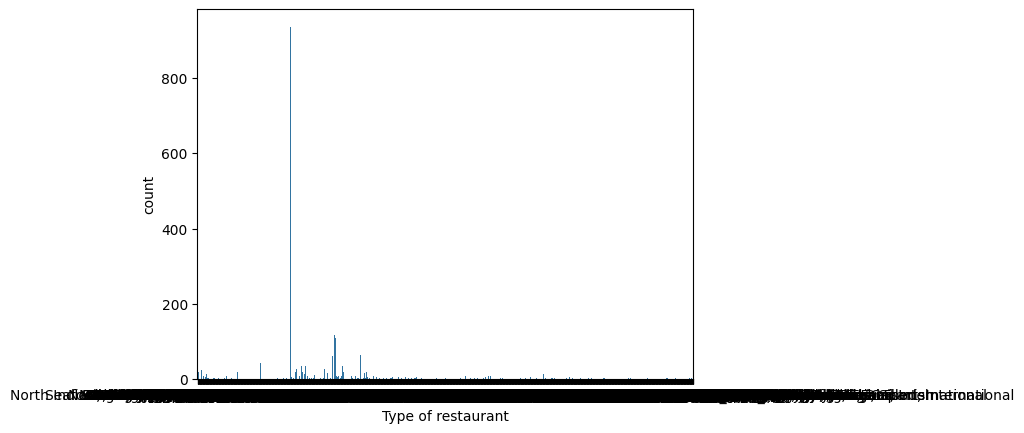

In [ ]:
sns.countplot(x=dataframe['Cuisines'])
plt.xlabel("Type of restaurant")

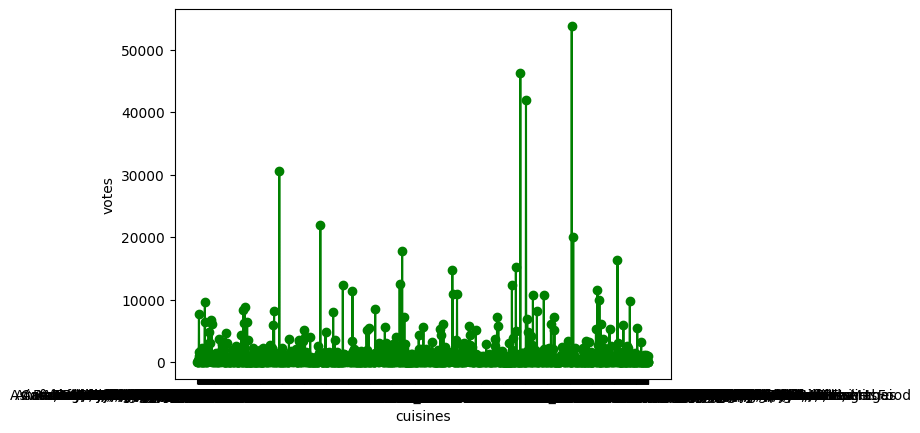

In [ ]:
grouped_data= dataframe.groupby('Cuisines')['Votes'].sum()
rescult= pd.DataFrame({'votes': grouped_data.values, 'cuisines': grouped_data.index})
plt.plot(rescult['cuisines'], rescult['votes'], color='green', marker='o')
plt.xlabel('cuisines')
plt.ylabel('votes')
plt.show()

In [ ]:
max_votes = dataframe['Votes'].max()
restaurant_with_max_votes = dataframe.loc[dataframe['Votes'] == max_votes, 'Restaurant Name']

print('Restaurant(s) with the maximum votes:')
print(restaurant_with_max_votes)

Restaurant(s) with the maximum votes:
728    Toit
Name: Restaurant Name, dtype: object


<Axes: xlabel='Country Code', ylabel='count'>

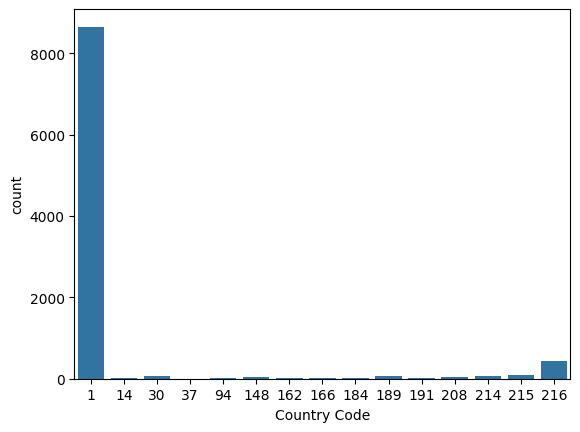

In [ ]:
sns.countplot(x=dataframe['Country Code'])

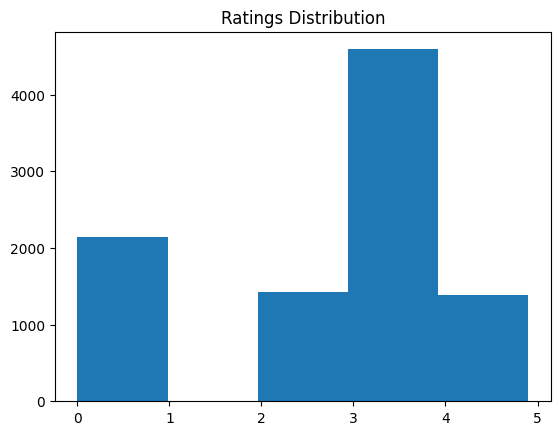

In [ ]:
plt.hist(dataframe['Aggregate rating'],bins=5)
plt.title('Ratings Distribution')
plt.show()

<Axes: xlabel='Average Cost for two', ylabel='count'>

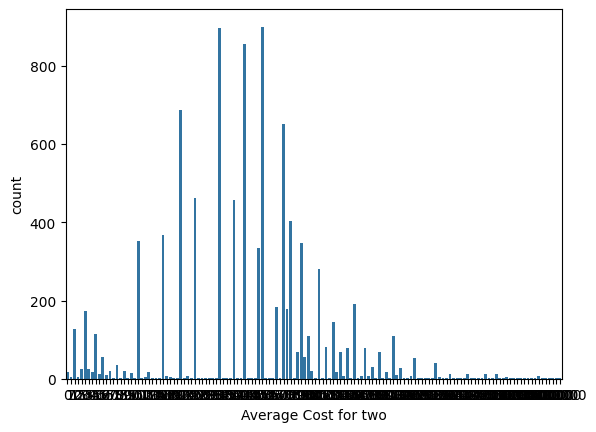

In [ ]:
couple_data=dataframe['Average Cost for two']
sns.countplot(x=couple_data)

<Axes: xlabel='Has Online delivery', ylabel='Aggregate rating'>

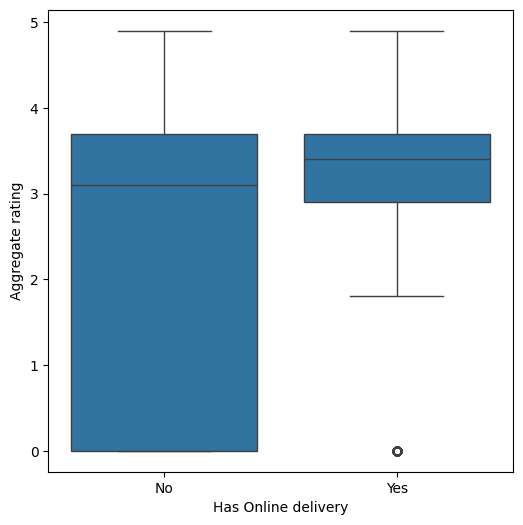

In [ ]:
plt.figure(figsize = (6,6))
sns.boxplot(x = 'Has Online delivery', y = 'Aggregate rating', data = dataframe)

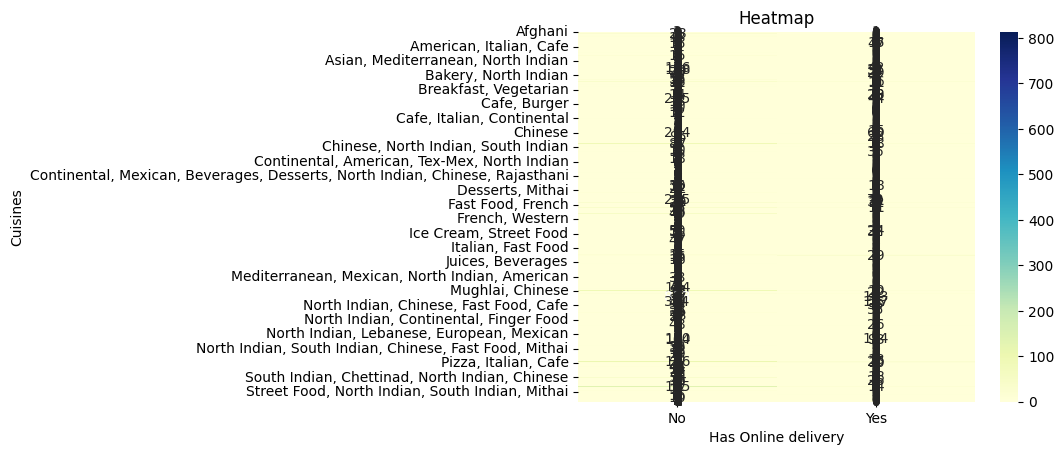

In [ ]:
pivot_table = dataframe.pivot_table(index='Cuisines', columns='Has Online delivery', aggfunc='size', fill_value=0)
sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt='d')
plt.title('Heatmap')
plt.xlabel('Has Online delivery')
plt.ylabel('Cuisines')
plt.show()